<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/quantum_field_theory/qft_colab_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Quantum Field Theory* — `qft_colab_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Quantum Field Theory — Colab Visualizations
**Tong (Cambridge) · PSE Lab · SeoulTech**

Figures saved to `figures/qft/`. Each cell is self-contained.

| Plot | Chapter | Topic |
|------|---------|-------|
| 1 | Ch 1 Classical FT | Klein-Gordon dispersion, Mexican hat potential, phase space |
| 2 | Ch 2 Canonical Quant. | Vacuum energy, Feynman propagator, normal ordering |
| 3 | Ch 3 Interacting | Perturbative expansion, Mandelstam variables, $d\sigma/d\Omega$ |
| 4 | Ch 4 Dirac Eq. | Dirac spectrum, $\gamma$-algebra, helicity-chirality |
| 5 | Ch 5 Dirac Field | Propagator poles, spin sums, $e^+e^-\to\mu^+\mu^-$ |
| 6 | Ch 6 QED | Running $\alpha$, vacuum polarization, Ward-Takahashi |
| 7 | All Ch | Dim. reg., $\beta$-function, running parameters |

---
## Plot 1 · Classical Field Theory (Ch 1)

**Left**: Klein-Gordon dispersion $\omega^2=k^2+m^2$. **Centre**: Mexican hat potential $V=(\phi^2-v^2)^2$ — spontaneous symmetry breaking. **Right**: 2-body phase space $|\mathbf{p}^*|$ as function of daughter mass.

  saved -> figures/qft/plot1_classical.png


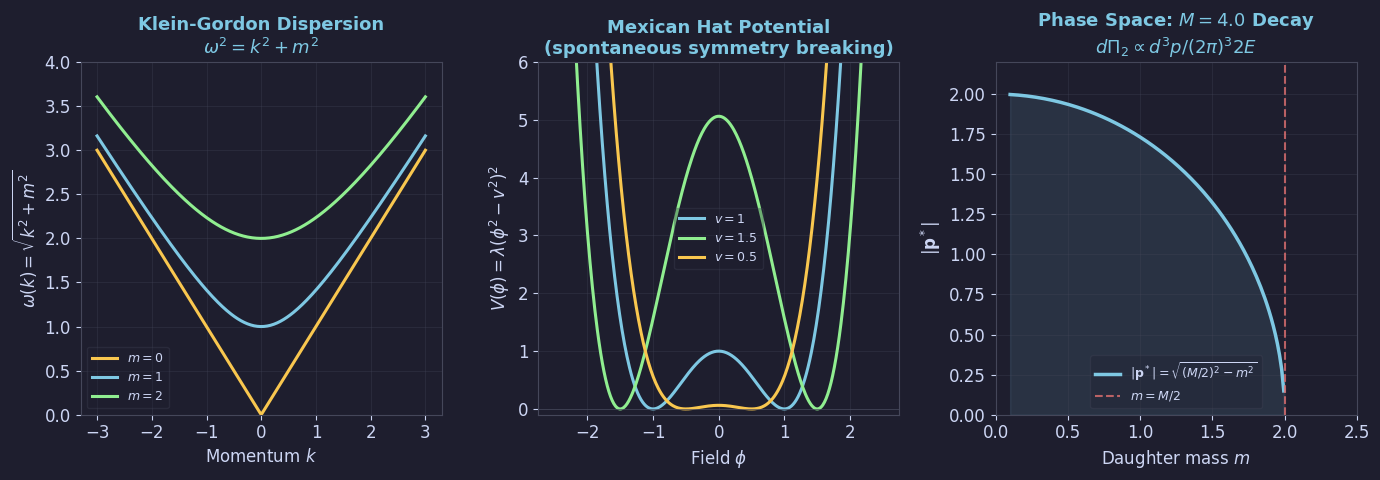

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import kv
from matplotlib.transforms import blended_transform_factory
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/qft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 1: Classical Field Theory (Ch 1) ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

k = np.linspace(-3, 3, 300)
ax = axes[0]
for m_val,col,lab in [(0,YELLOW,'$m=0$'),(1,BLUE,'$m=1$'),(2,GREEN,'$m=2$')]:
    ax.plot(k, np.sqrt(k**2+m_val**2), color=col, lw=2.2, label=lab)
ax.set_xlabel('Momentum $k$'); ax.set_ylabel(r'$\omega(k)=\sqrt{k^2+m^2}$')
ax.set_title('Klein-Gordon Dispersion\n'+r'$\omega^2=k^2+m^2$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True); ax.set_ylim(0,4)

phi = np.linspace(-2.5, 2.5, 400)
ax2 = axes[1]
for lam,v,col,lab in [(1,1,BLUE,'$v=1$'),(1,1.5,GREEN,'$v=1.5$'),(1,0.5,YELLOW,'$v=0.5$')]:
    ax2.plot(phi, lam*(phi**2-v**2)**2, color=col, lw=2.2, label=lab)
ax2.axhline(0, color=EDGE, lw=0.5)
ax2.set_xlabel(r'Field $\phi$'); ax2.set_ylabel(r'$V(\phi)=\lambda(\phi^2-v^2)^2$')
ax2.set_title('Mexican Hat Potential\n(spontaneous symmetry breaking)', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True); ax2.set_ylim(-0.1, 6)  # FIX: v=1.5 커브 최고점 표시

m_vals = np.linspace(0.1,3,200); M_decay=4.0
p_star = np.sqrt(np.maximum((M_decay/2)**2-m_vals**2,0))
ax3 = axes[2]
ax3.plot(m_vals[m_vals<M_decay/2], p_star[m_vals<M_decay/2],
         color=BLUE, lw=2.5, label=r'$|\mathbf{p}^*|=\sqrt{(M/2)^2-m^2}$')
ax3.axvline(M_decay/2, color=RED, lw=1.5, ls='--', alpha=0.8, label=f'$m=M/2$')
ax3.fill_between(m_vals[m_vals<M_decay/2], 0, p_star[m_vals<M_decay/2], color=BLUE, alpha=0.12)
ax3.set_xlabel('Daughter mass $m$'); ax3.set_ylabel(r'$|\mathbf{p}^*|$')
ax3.set_title(f'Phase Space: $M={M_decay}$ Decay\n'+r'$d\Pi_2\propto d^3p/(2\pi)^3 2E$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0, 2.5); ax3.set_ylim(0, 2.2)  # FIX
plt.tight_layout(pad=1.2)
save('plot1_classical.png', fig)


---
## Plot 2 · Canonical Quantization (Ch 2)

**Left**: Vacuum energy density $\rho\sim\Lambda^4$ — hierarchy problem. **Centre**: Feynman propagator (Euclidean 2D) — massive vs massless. **Right**: Normal ordering identities, CCRs, relativistic normalisation.

  saved -> figures/qft/plot2_quantization.png


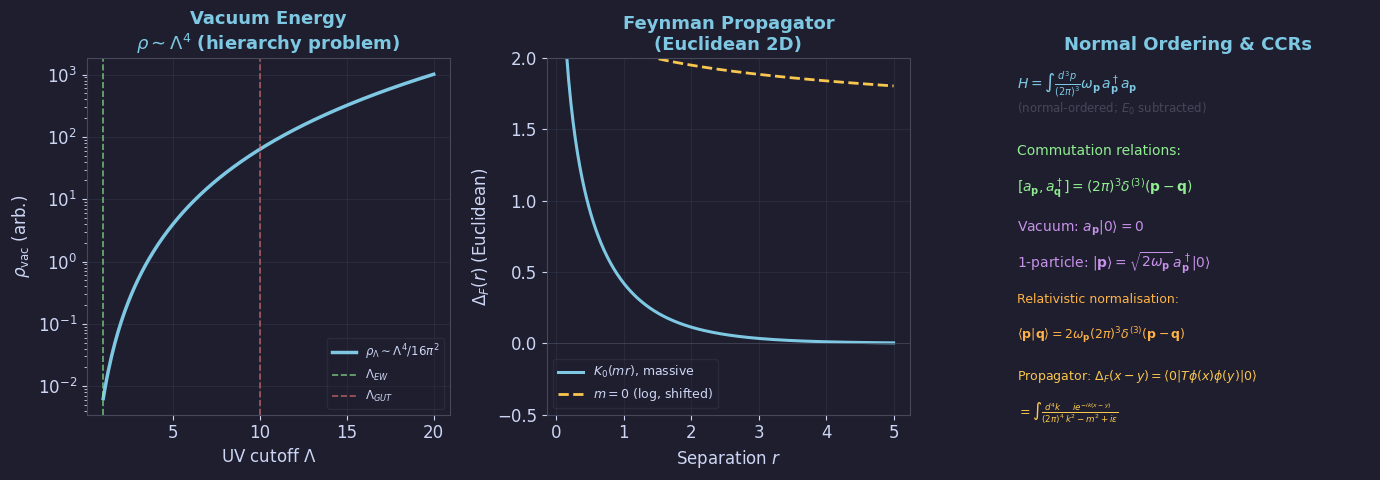

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import kv
from matplotlib.transforms import blended_transform_factory
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/qft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 2: Canonical Quantization (Ch 2) ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

Lambda_arr = np.linspace(1,20,200)
ax = axes[0]
ax.semilogy(Lambda_arr, Lambda_arr**4/(16*np.pi**2), color=BLUE, lw=2.5,
            label=r'$\rho_\Lambda\sim\Lambda^4/16\pi^2$')
ax.axvline(1,  color=GREEN, lw=1.2, ls='--', alpha=0.7, label='$\\Lambda_{EW}$')
ax.axvline(10, color=RED,   lw=1.2, ls='--', alpha=0.7, label='$\\Lambda_{GUT}$')
ax.set_xlabel('UV cutoff $\\Lambda$'); ax.set_ylabel(r'$\rho_{\rm vac}$ (arb.)')
ax.set_title('Vacuum Energy\n'+r'$\rho\sim\Lambda^4$ (hierarchy problem)', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True)

r = np.linspace(0.1,5,300); m_prop=1.0
K0_vals = kv(0, m_prop*r)
ax2 = axes[1]
ax2.plot(r, K0_vals, color=BLUE, lw=2.2, label='$K_0(mr)$, massive')
G0 = -np.log(r)/(2*np.pi)
shift = K0_vals[0] - G0[0]
ax2.plot(r, G0+shift, color=YELLOW, lw=2.0, ls='--', label='$m=0$ (log, shifted)')  # FIX: 정확한 shift
ax2.axhline(0, color=EDGE, lw=0.5)
ax2.set_xlabel('Separation $r$'); ax2.set_ylabel(r'$\Delta_F(r)$ (Euclidean)')
ax2.set_title('Feynman Propagator\n(Euclidean 2D)', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True); ax2.set_ylim(-0.5,2)

text_panel(axes[2], 'Normal Ordering & CCRs', [
    (r'$H=\int\frac{d^3p}{(2\pi)^3}\omega_\mathbf{p}\,a^\dagger_\mathbf{p}a_\mathbf{p}$', BLUE, 10),
    (r'(normal-ordered; $E_0$ subtracted)', EDGE, 8.5),
    ('', FG, 9),
    ('Commutation relations:', GREEN, 10),
    (r'$[a_\mathbf{p},a^\dagger_\mathbf{q}]=(2\pi)^3\delta^{(3)}(\mathbf{p}-\mathbf{q})$', GREEN, 10),
    ('', FG, 9),
    (r'Vacuum: $a_\mathbf{p}|0\rangle=0$', PURPLE, 10),
    (r'1-particle: $|\mathbf{p}\rangle=\sqrt{2\omega_\mathbf{p}}\,a^\dagger_\mathbf{p}|0\rangle$', PURPLE, 10),
    ('', FG, 9),
    ('Relativistic normalisation:', ORANGE, 9),
    (r'$\langle\mathbf{p}|\mathbf{q}\rangle=2\omega_\mathbf{p}(2\pi)^3\delta^{(3)}(\mathbf{p}-\mathbf{q})$', ORANGE, 9),
    ('', FG, 9),
    (r'Propagator: $\Delta_F(x-y)=\langle0|T\phi(x)\phi(y)|0\rangle$', YELLOW, 9),
    (r'$=\int\frac{d^4k}{(2\pi)^4}\frac{ie^{-ik(x-y)}}{k^2-m^2+i\varepsilon}$', YELLOW, 9),
])
plt.tight_layout(pad=1.2)
save('plot2_quantization.png', fig)


---
## Plot 3 · Interacting Fields (Ch 3)

**Left**: Perturbative expansion in $\phi^4$ coupling. **Centre**: Mandelstam variables $t,u$ vs scattering angle. **Right**: Differential cross section — contact + $t$-channel exchange.

  saved -> figures/qft/plot3_interacting.png


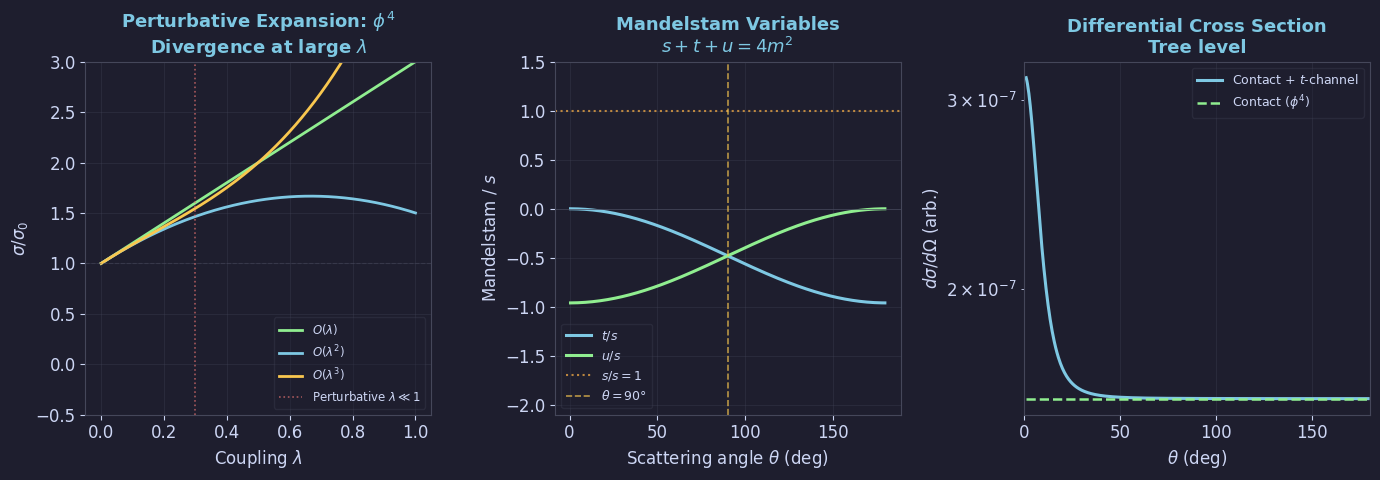

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import kv
from matplotlib.transforms import blended_transform_factory
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/qft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 3: Interacting Fields (Ch 3) ─────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

lam_g = np.linspace(0,1,200); s0=1.0
ax = axes[0]
ax.plot(lam_g, s0*(1+2.0*lam_g),                     color=GREEN,  lw=2.0, label='$O(\\lambda)$')
ax.plot(lam_g, s0*(1+2.0*lam_g-1.5*lam_g**2),        color=BLUE,   lw=2.0, label='$O(\\lambda^2)$')
ax.plot(lam_g, s0*(1+2.0*lam_g-1.5*lam_g**2+3*lam_g**3), color=YELLOW,lw=2.0, label='$O(\\lambda^3)$')
ax.axhline(s0, color=EDGE, lw=0.8, ls='--', alpha=0.5)
ax.axvline(0.3, color=RED, lw=1.2, ls=':', alpha=0.7, label='Perturbative $\\lambda\\ll1$')
ax.set_xlabel('Coupling $\\lambda$'); ax.set_ylabel(r'$\sigma/\sigma_0$')
ax.set_title(r'Perturbative Expansion: $\phi^4$'+'\nDivergence at large $\\lambda$', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True); ax.set_ylim(-0.5,3)

theta = np.linspace(0.01,np.pi-0.01,300)
E_cm=10.0; m=1.0; p=np.sqrt((E_cm/2)**2-m**2)
t_val = -(2*p**2)*(1-np.cos(theta))
u_val = -(2*p**2)*(1+np.cos(theta))
ax2 = axes[1]
ax2.plot(np.degrees(theta), t_val/E_cm**2, color=BLUE,  lw=2.2, label='$t/s$')
ax2.plot(np.degrees(theta), u_val/E_cm**2, color=GREEN, lw=2.2, label='$u/s$')
ax2.axhline(1.0, color=ORANGE, lw=1.5, ls=':', alpha=0.7, label='$s/s=1$')  # FIX
ax2.axhline(0, color=EDGE, lw=0.5)
ax2.axvline(90, color=YELLOW, lw=1.2, ls='--', alpha=0.7, label='$\\theta=90°$')
ax2.set_xlabel(r'Scattering angle $\theta$ (deg)')
ax2.set_ylabel('Mandelstam / $s$')
ax2.set_title('Mandelstam Variables\n$s+t+u=4m^2$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_ylim(-2.1, 1.5)  # FIX

theta2=np.linspace(np.radians(1), np.radians(179), 500); lam4=0.1  # FIX: θ=0 극 발산 제거
t_m=-(2*p**2)*(1-np.cos(theta2))
M2_contact=lam4**2*np.ones_like(theta2)
M2_exch=(lam4/(t_m-1.0))**2
dsig=(M2_contact+M2_exch)/(64*np.pi**2*E_cm**2)
ax3 = axes[2]
ax3.semilogy(np.degrees(theta2), dsig,               color=BLUE,  lw=2.2, label='Contact + $t$-channel')
ax3.semilogy(np.degrees(theta2), M2_contact/(64*np.pi**2*E_cm**2)*np.ones_like(theta2),
             color=GREEN, lw=1.8, ls='--', label='Contact ($\\phi^4$)')
ax3.set_xlabel(r'$\theta$ (deg)'); ax3.set_ylabel(r'$d\sigma/d\Omega$ (arb.)')
ax3.set_title(r'Differential Cross Section'+'\nTree level', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0, 180)  # FIX
plt.tight_layout(pad=1.2)
save('plot3_interacting.png', fig)


---
## Plot 4 · The Dirac Equation (Ch 4)

**Left**: Dirac spectrum — positive/negative energy, gap $2m$. **Centre**: $\gamma$-matrix algebra, Weyl/Dirac reps, $\gamma^5$. **Right**: Helicity-chirality alignment $p/E\to1$ as $E\gg m$.

  saved -> figures/qft/plot4_dirac.png


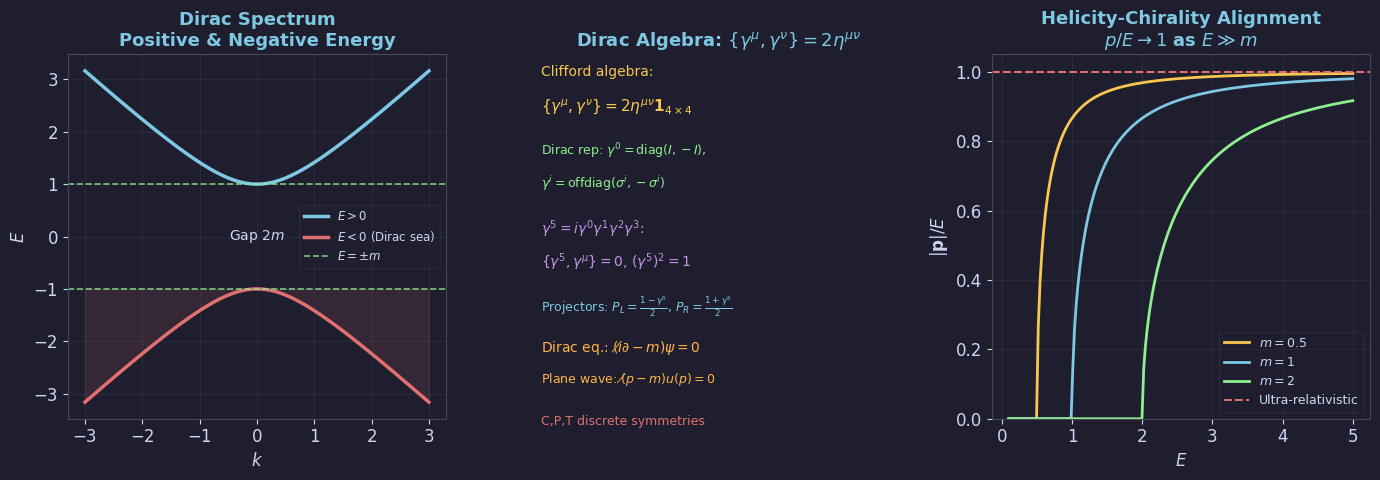

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import kv
from matplotlib.transforms import blended_transform_factory
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/qft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 4: The Dirac Equation (Ch 4) ─────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

k=np.linspace(-3,3,300); m_d=1.0
ax=axes[0]
ax.plot(k,  np.sqrt(k**2+m_d**2), color=BLUE, lw=2.5, label='$E>0$')
ax.plot(k, -np.sqrt(k**2+m_d**2), color=RED,  lw=2.5, label='$E<0$ (Dirac sea)')
ax.fill_between(k, -np.sqrt(k**2+m_d**2), -m_d, color=RED, alpha=0.12)
ax.axhline( m_d, color=GREEN, lw=1.2, ls='--', alpha=0.8, label=r'$E=\pm m$')
ax.axhline(-m_d, color=GREEN, lw=1.2, ls='--', alpha=0.8)
ax.text(0,0,'Gap $2m$',ha='center',va='center',color=FG,fontsize=10)
ax.set_xlabel('$k$'); ax.set_ylabel('$E$')
ax.set_title('Dirac Spectrum\nPositive & Negative Energy', color=BLUE)
ax.legend(fontsize=8.5,labelcolor=FG); ax.grid(True)

text_panel(axes[1], r'Dirac Algebra: $\{\gamma^\mu,\gamma^\nu\}=2\eta^{\mu\nu}$', [
    (r'Clifford algebra:', YELLOW, 10),
    (r'$\{\gamma^\mu,\gamma^\nu\}=2\eta^{\mu\nu}\mathbf{1}_{4\times4}$', YELLOW, 11),
    ('', FG, 9),
    (r'Dirac rep: $\gamma^0=\mathrm{diag}(I,-I)$,', GREEN, 9),
    (r'$\gamma^i=\mathrm{offdiag}(\sigma^i,-\sigma^i)$', GREEN, 9),
    ('', FG, 9),
    (r'$\gamma^5=i\gamma^0\gamma^1\gamma^2\gamma^3$:', PURPLE, 10),
    (r'$\{\gamma^5,\gamma^\mu\}=0$, $(\gamma^5)^2=1$', PURPLE, 10),
    ('', FG, 9),
    (r'Projectors: $P_L=\frac{1-\gamma^5}{2}$, $P_R=\frac{1+\gamma^5}{2}$', BLUE, 9),
    ('', FG, 9),
    (r'Dirac eq.: $(i\not\partial-m)\psi=0$', ORANGE, 10),
    (r'Plane wave: $(\not p-m)u(p)=0$', ORANGE, 9),
    ('', FG, 9),
    (r'C,P,T discrete symmetries', RED, 9),
])

E_hel=np.linspace(0.1,5,200)
ax3=axes[2]
for m_v,col,lab in [(0.5,YELLOW,'$m=0.5$'),(1.0,BLUE,'$m=1$'),(2.0,GREEN,'$m=2$')]:
    p_E=np.sqrt(np.maximum(E_hel**2-m_v**2,0))/E_hel
    ax3.plot(E_hel,p_E,color=col,lw=2.0,label=lab)
ax3.axhline(1.0,color=RED,lw=1.5,ls='--',label='Ultra-relativistic')
ax3.set_xlabel('$E$'); ax3.set_ylabel(r'$|\mathbf{p}|/E$')
ax3.set_title('Helicity-Chirality Alignment\n$p/E\\to1$ as $E\\gg m$', color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG); ax3.grid(True); ax3.set_ylim(0,1.05)
plt.tight_layout(pad=1.2)
save('plot4_dirac.png', fig)


---
## Plot 5 · Quantizing the Dirac Field (Ch 5)

**Left**: Feynman propagator poles in complex $k^0$ plane — contour prescription. **Centre**: Spin sum identities, Dirac propagator, anti-commutation. **Right**: $\sigma(e^+e^-\to\mu^+\mu^-)\propto1/s$.

  saved -> figures/qft/plot5_dirac_field.png


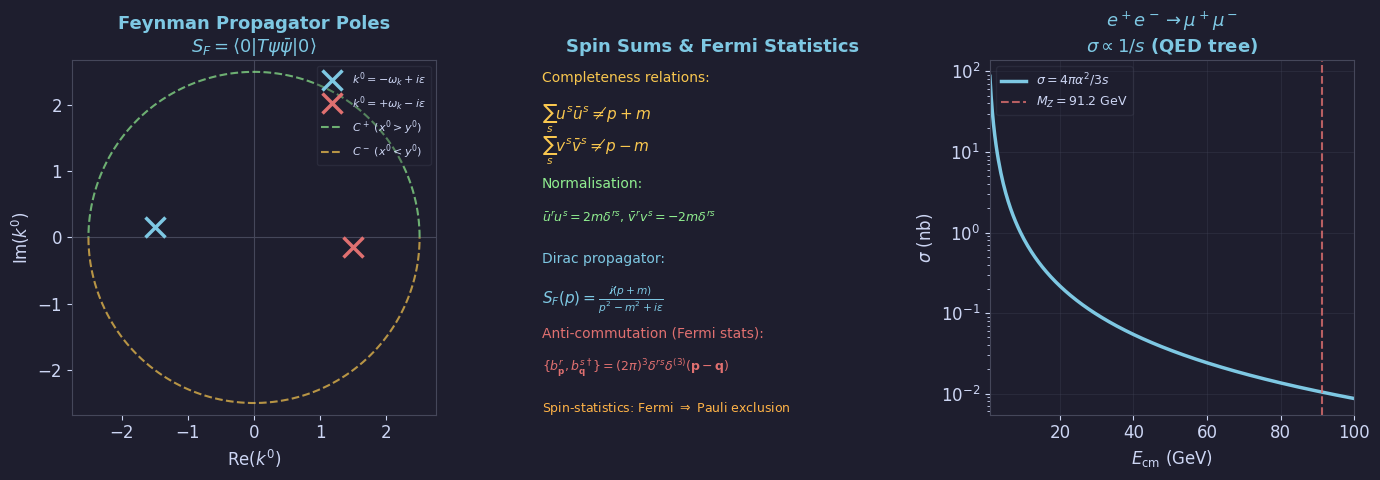

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import kv
from matplotlib.transforms import blended_transform_factory
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/qft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 5: Quantizing the Dirac Field (Ch 5) ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

ax=axes[0]
ax.set_xlim(-3,3); ax.set_ylim(-2,2); ax.axis('equal')
ax.axhline(0,color=EDGE,lw=0.8); ax.axvline(0,color=EDGE,lw=0.8)
# FIX: Feynman prescription 극 위치 수정
ax.plot([-1.5],[ 0.15],'x',color=BLUE,ms=14,mew=2.5,label=r'$k^0=-\omega_k+i\varepsilon$')
ax.plot([ 1.5],[-0.15],'x',color=RED, ms=14,mew=2.5,label=r'$k^0=+\omega_k-i\varepsilon$')
R=2.5; theta_c=np.linspace(0,np.pi,100)
ax.plot(R*np.cos(theta_c),R*np.sin(theta_c),color=GREEN,lw=1.5,ls='--',alpha=0.7,label='$C^+$ ($x^0>y^0$)')
ax.plot(R*np.cos(theta_c+np.pi),R*np.sin(theta_c+np.pi),color=YELLOW,lw=1.5,ls='--',alpha=0.7,label='$C^-$ ($x^0<y^0$)')
ax.set_xlabel(r'Re$(k^0)$'); ax.set_ylabel(r'Im$(k^0)$')
ax.set_title('Feynman Propagator Poles\n'+r'$S_F=\langle0|T\psi\bar\psi|0\rangle$', color=BLUE)
ax.legend(fontsize=8,labelcolor=FG,loc='upper right')

text_panel(axes[1], 'Spin Sums & Fermi Statistics', [
    (r'Completeness relations:', YELLOW, 10),
    (r'$\sum_s u^s\bar u^s=\not p+m$', YELLOW, 11),
    (r'$\sum_s v^s\bar v^s=\not p-m$', YELLOW, 11),
    ('', FG, 9),
    ('Normalisation:', GREEN, 10),
    (r'$\bar u^r u^s=2m\delta^{rs}$, $\bar v^r v^s=-2m\delta^{rs}$', GREEN, 9),
    ('', FG, 9),
    ('Dirac propagator:', BLUE, 10),
    (r'$S_F(p)=\frac{i(\not p+m)}{p^2-m^2+i\varepsilon}$', BLUE, 11),
    ('', FG, 9),
    ('Anti-commutation (Fermi stats):', RED, 10),
    (r'$\{b^r_\mathbf{p},b^{s\dagger}_\mathbf{q}\}=(2\pi)^3\delta^{rs}\delta^{(3)}(\mathbf{p}-\mathbf{q})$', RED, 9),
    ('', FG, 9),
    (r'Spin-statistics: Fermi $\Rightarrow$ Pauli exclusion', ORANGE, 9),
])

E_cm=np.linspace(1,100,300); alpha_em=1/137  # FIX: M_Z=91.2 GeV 가시 범위로 확장
sigma_nb=4*np.pi*alpha_em**2/(3*E_cm**2)*0.3894e6
ax3=axes[2]
ax3.semilogy(E_cm,sigma_nb,color=BLUE,lw=2.5,label=r'$\sigma=4\pi\alpha^2/3s$')
ax3.axvline(91.2,color=RED,lw=1.5,ls='--',alpha=0.8,label='$M_Z=91.2$ GeV')
ax3.set_xlabel(r'$E_{\rm cm}$ (GeV)'); ax3.set_ylabel(r'$\sigma$ (nb)')
ax3.set_title(r'$e^+e^-\to\mu^+\mu^-$'+'\n'+r'$\sigma\propto1/s$ (QED tree)', color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG); ax3.grid(True)
ax3.set_xlim(1, 100)  # FIX
plt.tight_layout(pad=1.2)
save('plot5_dirac_field.png', fig)


---
## Plot 6 · Quantum Electrodynamics (Ch 6)

**Left**: Running coupling $\alpha(\mu)$ — 1-loop QED, $\ln(\mu^2/m_e^2)$. **Centre**: Vacuum polarization $\Pi(q^2)$ — real and imaginary parts. **Right**: Ward-Takahashi identity consequences.

  saved -> figures/qft/plot6_qed.png


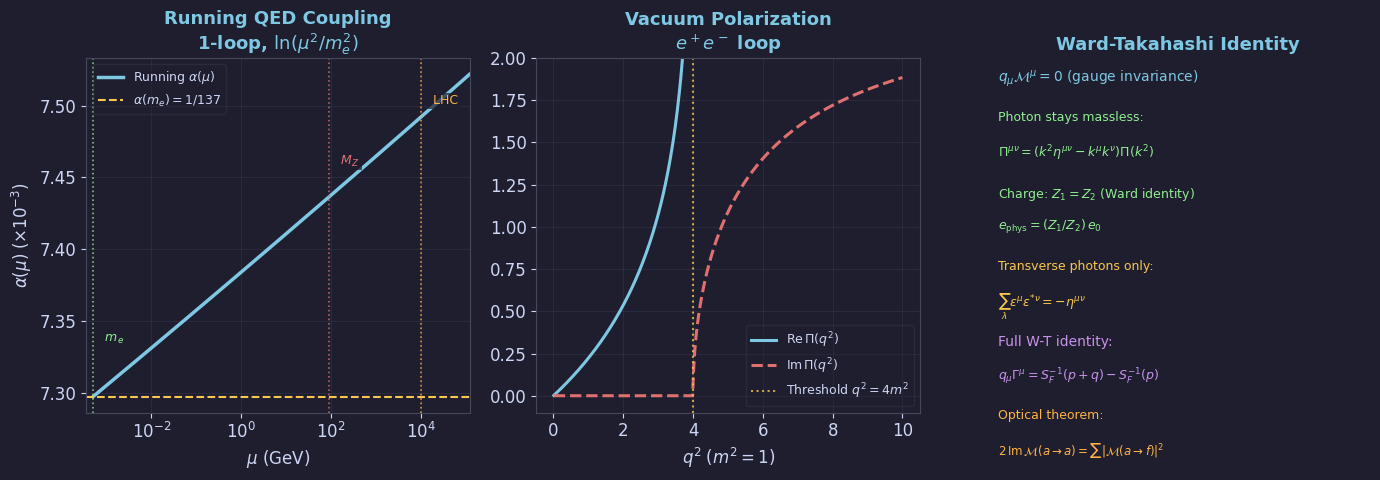

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import kv
from matplotlib.transforms import blended_transform_factory
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/qft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 6: Quantum Electrodynamics (Ch 6) ────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

m_e=0.511e-3; alpha0=1/137.036
mu=np.logspace(np.log10(m_e),np.log10(1.2e5),500)
alpha_run=alpha0/(1-(alpha0/(3*np.pi))*2*np.log(mu/m_e))
alpha_run=np.where(alpha_run>0.05,np.nan,alpha_run)
ax=axes[0]
ax.plot(mu,alpha_run*1e3,color=BLUE,lw=2.5,label=r'Running $\alpha(\mu)$')
ax.axhline(alpha0*1e3,color=YELLOW,lw=1.5,ls='--',label=r'$\alpha(m_e)=1/137$')
trans=blended_transform_factory(ax.transData,ax.transAxes)
for mu_v,lab,col,ly in [(m_e,r'$m_e$',GREEN,0.2),(91.2,r'$M_Z$',RED,0.7),(1e4,'LHC',ORANGE,0.87)]:
    ax.axvline(mu_v,color=col,lw=1.2,ls=':',alpha=0.8)
    ax.text(mu_v*1.5,ly,f' {lab}',transform=trans,color=col,fontsize=9,ha='left',
            bbox=dict(facecolor=BG,alpha=0.7,edgecolor='none',pad=1))
ax.set_xscale('log'); ax.set_xlabel(r'$\mu$ (GeV)')
ax.set_ylabel(r'$\alpha(\mu)\;(\times10^{-3})$')
ax.set_title('Running QED Coupling\n1-loop, $\\ln(\\mu^2/m_e^2)$',color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True); ax.set_xlim(m_e*0.7,1.2e5)

q2=np.linspace(0.01,10,300); m2=1.0
Pi_re=(1/137)/(3*np.pi)*np.log(np.maximum(4*m2/np.maximum(4*m2-q2,0.01),1))
Pi_im=np.where(q2>4*m2,(1/137)/(3*np.pi)*np.pi*np.sqrt(np.maximum(1-4*m2/q2,0)),0)
ax2=axes[1]
ax2.plot(q2,Pi_re*1e3,color=BLUE,lw=2.2,label=r'Re$\,\Pi(q^2)$')
ax2.plot(q2,Pi_im*1e3,color=RED,lw=2.2,ls='--',label=r'Im$\,\Pi(q^2)$')
ax2.axvline(4*m2,color=YELLOW,lw=1.5,ls=':',alpha=0.8,label=r'Threshold $q^2=4m^2$')
ax2.set_xlabel(r'$q^2\;(m^2=1)$')  # FIX: 축 라벨 수정; ax2.set_ylabel(r'$\Pi(q^2)\;(\times10^{-3})$')
ax2.set_title('Vacuum Polarization\n'+r'$e^+e^-$ loop', color=BLUE)
ax2.legend(fontsize=9,labelcolor=FG); ax2.grid(True)
ax2.set_ylim(-0.1, 2.0)  # FIX: log 발산 제어

text_panel(axes[2], 'Ward-Takahashi Identity', [
    (r'$q_\mu\mathcal{M}^\mu=0$ (gauge invariance)', BLUE, 10),
    ('', FG, 8),
    (r'Photon stays massless:', GREEN, 9),
    (r'$\Pi^{\mu\nu}=(k^2\eta^{\mu\nu}-k^\mu k^\nu)\Pi(k^2)$', GREEN, 9),
    ('', FG, 8),
    (r'Charge: $Z_1=Z_2$ (Ward identity)', GREEN, 9),
    (r'$e_{\rm phys}=(Z_1/Z_2)\,e_0$', GREEN, 9),
    ('', FG, 8),
    (r'Transverse photons only:', YELLOW, 9),
    (r'$\sum_\lambda\varepsilon^\mu\varepsilon^{*\nu}=-\eta^{\mu\nu}$', YELLOW, 9),
    ('', FG, 8),
    (r'Full W-T identity:', PURPLE, 10),
    (r'$q_\mu\Gamma^\mu=S_F^{-1}(p+q)-S_F^{-1}(p)$', PURPLE, 9),
    ('', FG, 8),
    (r'Optical theorem:', ORANGE, 9),
    (r'$2\,\mathrm{Im}\,\mathcal{M}(a\to a)=\sum|\mathcal{M}(a\to f)|^2$', ORANGE, 8.5),
])
plt.tight_layout(pad=1.2)
save('plot6_qed.png', fig)


---
## Plot 7 · Renormalisation (Ch 2–6)

**Left**: Dim. reg. $1/\varepsilon$ pole — UV divergence structure. **Centre**: $\beta$-function — QED Landau pole ($\beta>0$) vs QCD asymptotic freedom ($\beta<0$). **Right**: Running $m(\mu)$ and $\lambda(\mu)$ in $\phi^4$.

  saved -> figures/qft/plot7_renorm.png


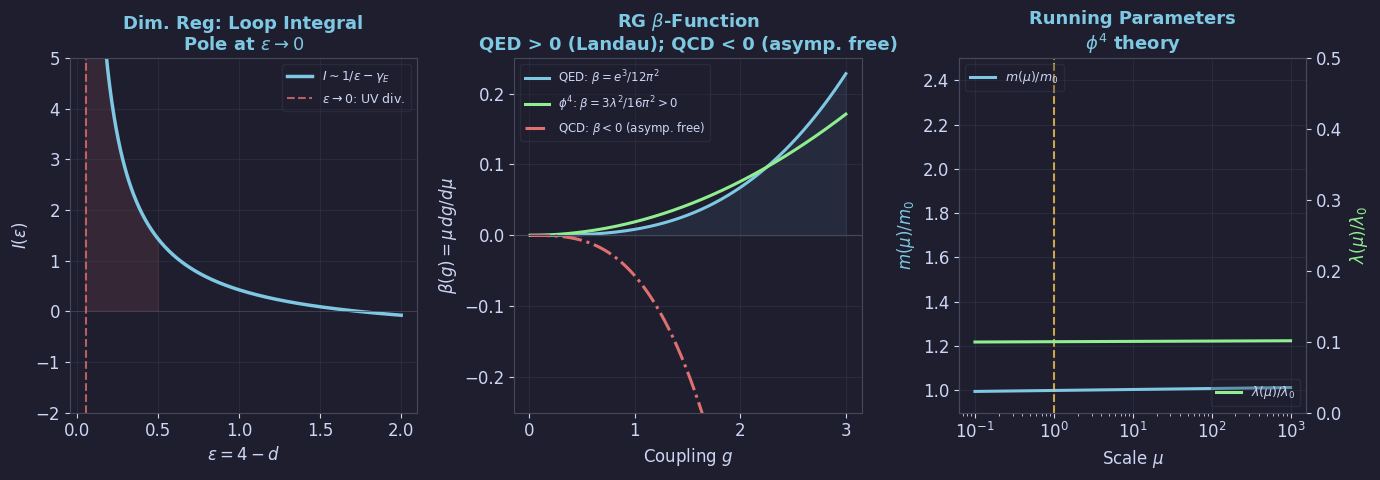

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import kv
from matplotlib.transforms import blended_transform_factory
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/qft'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

def text_panel(ax, title, items):
    ax.axis('off'); ax.set_title(title, color=BLUE)
    y=0.97
    for txt,col,fs in items:
        ax.text(0.03,y,txt,transform=ax.transAxes,color=col,fontsize=fs,va='top')
        y -= 0.09 if txt else 0.03

# ── Plot 7: Renormalisation (Ch 2–6) ──────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

eps_arr=np.linspace(0.05,2.0,300)
ax=axes[0]
ax.plot(eps_arr,1/eps_arr-0.5772,color=BLUE,lw=2.5,label=r'$I\sim1/\varepsilon-\gamma_E$')
ax.axhline(0,color=EDGE,lw=0.5)
ax.axvline(0.05,color=RED,lw=1.5,ls='--',alpha=0.8,label='$\\varepsilon\\to0$: UV div.')
ax.fill_between(eps_arr[eps_arr<0.5],1/eps_arr[eps_arr<0.5]-0.5772,0,color=RED,alpha=0.12)
ax.set_xlabel(r'$\varepsilon=4-d$'); ax.set_ylabel(r'$I(\varepsilon)$')
ax.set_title('Dim. Reg: Loop Integral\n'+r'Pole at $\varepsilon\to0$', color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True); ax.set_ylim(-2,5)

g_arr=np.linspace(0.01,3,300)
ax2=axes[1]
ax2.plot(g_arr,g_arr**3/(12*np.pi**2),  color=BLUE, lw=2.2,label=r'QED: $\beta=e^3/12\pi^2$')
ax2.plot(g_arr,3*g_arr**2/(16*np.pi**2),color=GREEN,lw=2.2,label=r'$\phi^4$: $\beta=3\lambda^2/16\pi^2>0$')
# FIX: QCD β 추가 (Nc=3, Nf=3)
beta_qcd = -(11*3/3 - 2*3/3)*g_arr**3/(16*np.pi**2)
ax2.plot(g_arr, beta_qcd, color=RED, lw=2.2, ls='-.', label=r'QCD: $\beta<0$ (asymp. free)')
ax2.axhline(0,color=EDGE,lw=0.8)
ax2.fill_between(g_arr,0,g_arr**3/(12*np.pi**2),color=BLUE,alpha=0.08)
ax2.set_xlabel('Coupling $g$'); ax2.set_ylabel(r'$\beta(g)=\mu\,dg/d\mu$')
ax2.set_title('RG $\\beta$-Function\nQED > 0 (Landau); QCD < 0 (asymp. free)',color=BLUE)
ax2.legend(fontsize=8.5,labelcolor=FG); ax2.grid(True); ax2.set_ylim(-0.25,0.25)  # FIX

mu_arr=np.logspace(-1,3,200); lam=0.1; gm=3*lam/(16*np.pi**2)
lam_run=lam/(1-3*lam/(16*np.pi**2)*np.log(mu_arr/1.0))
lam_run=np.where(lam_run>5,np.nan,lam_run)
ax3=axes[2]; ax3t=ax3.twinx()
ax3.plot(mu_arr, (mu_arr/1.0)**gm,  color=BLUE,  lw=2.2, label='$m(\\mu)/m_0$')
ax3t.plot(mu_arr,lam_run,             color=GREEN, lw=2.2, label='$\\lambda(\\mu)/\\lambda_0$')
ax3.axvline(1.0,color=YELLOW,lw=1.5,ls='--',alpha=0.8)
ax3.set_xscale('log'); ax3.set_xlabel('Scale $\\mu$')
ax3.set_ylabel('$m(\\mu)/m_0$',color=BLUE); ax3t.set_ylabel('$\\lambda(\\mu)/\\lambda_0$',color=GREEN)
ax3.set_title('Running Parameters\n'+r'$\phi^4$ theory',color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG,loc='upper left')
ax3t.legend(fontsize=9,labelcolor=FG,loc='lower right')
ax3.set_ylim(0.9, 2.5); ax3t.set_ylim(0, 0.5)  # FIX
ax3.grid(True)
plt.tight_layout(pad=1.2)
save('plot7_renorm.png', fig)


---
## Download All Figures

In [8]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/qft'
saved=sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) if os.path.exists(OUTDIR) else []
print(f'Found {len(saved)} figures:')
for f in saved: print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')
zip_name='qft_colab_visualizations.zip'
with zipfile.ZipFile(zip_name,'w',zipfile.ZIP_DEFLATED) as zf:
    for fname in saved: zf.write(f'{OUTDIR}/{fname}',arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 7 figures:
  plot1_classical.png  (250 KB)
  plot2_quantization.png  (179 KB)
  plot3_interacting.png  (171 KB)
  plot4_dirac.png  (180 KB)
  plot5_dirac_field.png  (175 KB)
  plot6_qed.png  (190 KB)
  plot7_renorm.png  (171 KB)
Zip: qft_colab_visualizations.zip  (1252 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>